# Figure 3, Panel D

Lineplots of median ± IQR log2FC accessibility at active and primed enh over BAFinh timecourse or varied dose. 

*Output: lineplot_time_dose_enh_median_IQR.pdf*

# Setup

In [1]:
library(tidyverse)
library(patchwork)
library(here)
here::i_am("figures/Figure3/PanelD/PanelD.ipynb")
theme_set(theme_bw() + theme(panel.grid=element_blank(), text=element_text(size=15)))
sessionInfo()

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/figures/Figure3/PanelD

here() starts at /mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics



R version 4.2.2 Patched (2022-11-10 r83330)
Platform: x86_64-pc-linux-gnu (64-bit)
Running under: Ubuntu 23.04

Matrix products: default
BLAS:   /usr/lib/x86_64-linux-gnu/openblas-pthread/libblas.so.3
LAPACK: /usr/lib/x86_64-linux-gnu/openblas-pthread/libopenblasp-r0.3.21.so

locale:
 [1] LC_CTYPE=C.UTF-8       LC_NUMERIC=C           LC_TIME=C.UTF-8       
 [4] LC_COLLATE=C.UTF-8     LC_MONETARY=C.UTF-8    LC_MESSAGES=C.UTF-8   
 [7] LC_PAPER=C.UTF-8       LC_NAME=C              LC_ADDRESS=C          
[10] LC_TELEPHONE=C         LC_MEASUREMENT=C.UTF-8 LC_IDENTIFICATION=C   

attached base packages:
[1] stats     graphics  grDevices utils     datasets  methods   base     

other attached packages:
 [1] here_1.0.2      patchwork_1.3.0 lubridate_1.9.4 forcats_1.0.0  
 [5] stringr_1.5.1   dplyr_1.1.4     purrr_1.0.2     readr_2.1.5    
 [9] tidyr_1.3.1     tibble_3.2.1    ggplot2_3.5.2   tidyverse_2.0.0

loaded via a namespace (and not attached):
 [1] pillar_1.9.0      compiler_4.2.2    ba

# Load data

In [2]:
# BAFinh timecourse data
# get list of files
timecourse_files <- list.files(
    path      = here("inputs", "DARs"),
    pattern   = "^time.*tsv$",
    full.name = TRUE
)[c(1, 2, 4, 5, 3)]

labels <- c("t0.5", "t1", "t2", "t6", "t24")

# generate table of log2FCs (BAFinh vs vehicle) by time
timecourse_lfc <- read.delim(
    here("inputs", "bed", "ATAC_peaks", "filtered", "consensus_filt_annot.tsv"),
    sep = "\t")[, c(1:3, 12)] %>%
    arrange(seqnames, start) %>%
        mutate(type = case_when(type == "active_enh" ~ "active_enh", type == "poised_enh" ~ "primed_enh"))

timecourse_lfc$t0 <- 0

for (file in timecourse_files) {
    temp <- read.delim(file, sep = "\t") %>%
        arrange(seqnames, start)
    timecourse_lfc[[labels[which(timecourse_files == file)]]] <- temp$logFC
}

# titration data
# get list of files
titration_files <- list.files(
    path      = here("inputs", "DARs"),
    pattern   = "^dose.*tsv$",
    full.name = TRUE
)[c(2, 1, 4, 3)]

labels <- c("d10nM", "d100nM", "d1uM", "d10uM")

# generate table of log2FCs (BAFinh vs vehicle) by dose
titration_lfc <- read.delim(
    here("inputs", "bed", "ATAC_peaks", "filtered", "consensus_filt_annot.tsv"),
    sep = "\t"
)[, c(1:3, 12)] %>%
  arrange(seqnames, start) %>%
  mutate(type = case_when(type == "active_enh" ~ "active_enh", type == "poised_enh" ~ "primed_enh"))

titration_lfc$d0 <- 0

for (file in titration_files) {
    temp <- read.delim(file, sep = "\t") %>%
        arrange(seqnames, start)
    titration_lfc[[labels[which(titration_files == file)]]] <- temp$logFC
}


# Statistics
Wilcoxon rank-sum used to compare log2FC distributions between active and primed enhancers at each timepoint or dose. The largest (ie least significant) p-value after multiple testing correction (bonferroni) is reported for each experiment

In [3]:
#stats - timecourse
#Wilcoxon ranked sum test on each timepoint - report max(bonf adjusted pval)
library(dplyr)

pvals_time <- timecourse_lfc %>% filter(type %in% c("primed_enh", "active_enh")) %>% select(!c(seqnames,start,end, t0)) %>%
    pivot_longer(!type) %>%
    group_by(name) %>%
        summarize(
        w_pvalue = wilcox.test(value ~ type)$p.value
  )
pvals_time$p_adj <- p.adjust(pvals_time$w_pvalue, method = "bonferroni")
pval_time <- max(pvals_time$p_adj)

#stats - titration
pvals_dose <- titration_lfc %>% filter(type %in% c("primed_enh", "active_enh")) %>% select(!c(seqnames,start,end, d0)) %>%
    pivot_longer(!type) %>%
    group_by(name) %>%
        summarize(
        w_pvalue = wilcox.test(value ~ type)$p.value
  )
pvals_dose$p_adj <- p.adjust(pvals_dose$w_pvalue, method = "bonferroni")
pval_dose <- max(pvals_dose$p_adj)

# Generate plots and assemble figure panel

`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.
`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.


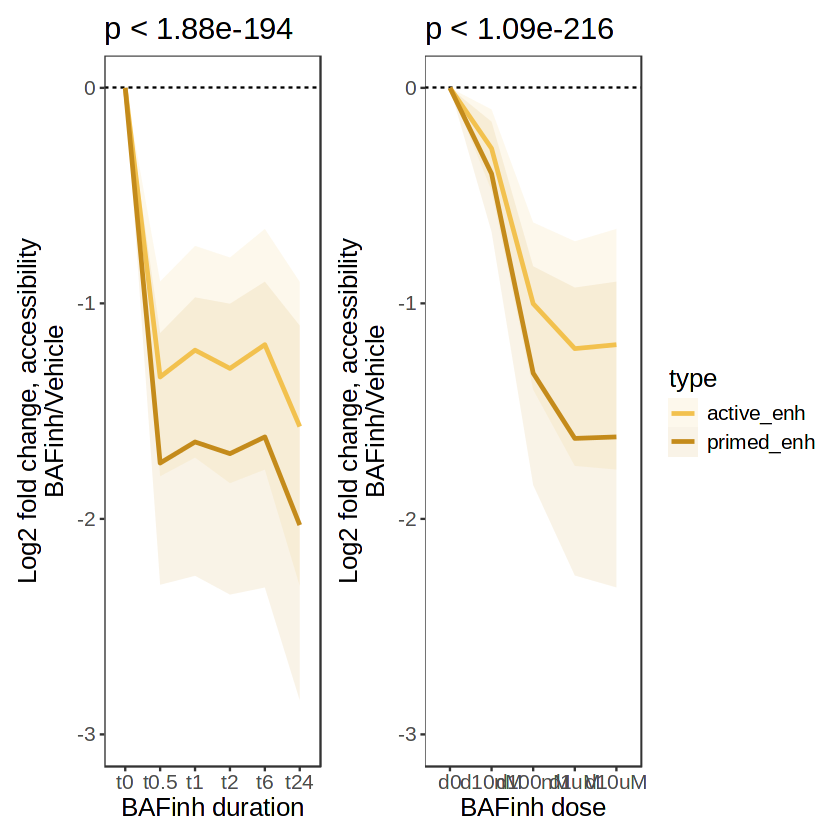

In [4]:
#plot median logFC with IQR
timecourse_plot_iqr <- timecourse_lfc %>% 
    filter(type %in% c("primed_enh", "active_enh")) %>% 
    select(!c(seqnames,start,end)) %>% pivot_longer(!type) %>% 
    group_by(type,name) %>% 
    summarize(median=median(value), pctile_25=quantile(value,0.25), pctile_75=quantile(value,0.75)) %>%
    ggplot(aes(fill=type,color=type,group=type, x=factor(name, levels=c("t0", "t0.5", "t1", "t2", "t6", "t24")))) +
    geom_hline(yintercept=0, linetype=2) + 
    geom_ribbon(aes(ymax=pctile_75, ymin=pctile_25), alpha=0.1, linewidth=0) +
    geom_line(aes(y=median), linewidth=1) +
    #geom_point(aes(y=median), size=2) +
    scale_color_manual(values=c("#f2c14e", "#c48b1b")) +
    scale_fill_manual(values=c("#f2c14e", "#c48b1b")) +
    coord_cartesian(ylim=c(-3,0)) +
    ggtitle(paste0("p < ", format(pval_time, digits=3))) +
    ylab("Log2 fold change, accessibility\nBAFinh/Vehicle") + 
    xlab("BAFinh duration") 

titration_plot_iqr <- titration_lfc %>% 
    filter(type %in% c("primed_enh", "active_enh")) %>% 
    select(!c(seqnames,start,end)) %>% pivot_longer(!type) %>% 
    group_by(type,name) %>% 
    summarize(median=median(value), pctile_25=quantile(value,0.25), pctile_75=quantile(value,0.75)) %>%
    ggplot(aes(fill=type,color=type,group=type, x=factor(name, levels=c("d0", "d10nM", "d100nM", "d1uM", "d10uM")))) + 
    geom_hline(yintercept=0, linetype=2) + 
    geom_ribbon(aes(ymax=pctile_75, ymin=pctile_25), alpha=0.1, linewidth=0) +
    geom_line(aes(y=median), linewidth=1) +
    #geom_point(aes(y=median), size=2) +
    scale_color_manual(values=c("#f2c14e", "#c48b1b")) +
    scale_fill_manual(values=c("#f2c14e", "#c48b1b")) +
    coord_cartesian(ylim=c(-3,0)) +
    ggtitle(paste0("p < ", format(pval_dose, digits=3)))+
    ylab("Log2 fold change, accessibility\nBAFinh/Vehicle") + 
    xlab("BAFinh dose") 

(timecourse_plot_iqr | titration_plot_iqr) + plot_layout(guides="collect")
ggsave("lineplot_time_dose_enh_median_IQR.pdf", height=4, width=9)